# Exercice 1 — MNIST au-delà de 97 %

**Hands-On ML, chapitre 3, exercice 1** · carnet CS229, bloc **B14**, étape 13 (option)

> *Essayez de construire un classifieur pour MNIST qui atteigne plus de 97 % d'accuracy sur le
> test set. Indice : `KNeighborsClassifier` fonctionne bien pour cette tâche ; il suffit de
> trouver de bonnes valeurs pour les hyperparamètres `weights` et `n_neighbors`.*

---

## Ce que cet exercice vous apprend vraiment

L'objectif affiché (97 %) n'est qu'un prétexte. Les trois leçons réelles sont ailleurs :

1. **Le k-nearest neighbors n'a pas de phase d'entraînement.** Il mémorise le training set et
   fait tout le travail au moment de la prédiction. Vous allez le sentir physiquement.
2. **Un grid search se valide sur un sous-échantillon avant d'être lancé en entier.** Lancer une
   grille de six heures pour découvrir une faute de frappe à la minute trois est une erreur qu'on
   ne commet qu'une fois.
3. **Le test set ne se touche qu'une seule fois**, tout à la fin. Tout le réglage se fait en
   cross-validation sur le training set (point **B13-6**).

## Durée

Comptez **1 h 30**, dont une bonne heure d'attente machine.

## Règle du jeu

À partir de la section 9 (« Évaluation finale »), on ne revient plus en arrière. Si le score
vous déplaît, c'est le score.

## Notation

Le carnet suit CS229 : $n$ exemples, $d$ features. Hands-On ML écrit $m$ exemples et $n$
features — les mêmes objets, les lettres échangées. Ici $n = 60\,000$ et $d = 784$.

---
## 1. Environnement

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams["figure.dpi"] = 110

print("numpy", np.__version__)

numpy 2.3.5


---
## 2. Chargement de MNIST

`fetch_openml` télécharge environ 55 Mo la première fois, puis met en cache dans
`~/scikit_learn_data`. Les appels suivants sont instantanés.

Deux arguments qui comptent :

- `as_frame=False` renvoie des tableaux NumPy plutôt qu'un DataFrame pandas. Pour 70 000 images
  de 784 pixels, le DataFrame est inutilement lourd et vous n'avez aucun usage des noms de
  colonnes `pixel1`, `pixel2`, ...
- `parser="auto"` évite un avertissement de dépréciation selon la version de scikit-learn.

In [2]:
mnist = fetch_openml("mnist_784", as_frame=False, parser="auto")

X, y = mnist.data, mnist.target
print("X :", X.shape, X.dtype)
print("y :", y.shape, y.dtype, "->", y[:10])

X : (70000, 784) int64
y : (70000,) object -> ['5' '0' '4' '1' '9' '2' '1' '3' '1' '4']


**Deux pièges dans ce que vous venez d'afficher.**

`y` contient des *chaînes de caractères* (`'5'`, `'0'`, ...), pas des entiers. Scikit-learn s'en
accommode pour la classification, mais un test comme `y_pred == 7` renverra `False` partout,
silencieusement.

`X` est en `float64` : $70\,000 \times 784 \times 8$ octets, soit 440 Mo. Or les pixels sont des
entiers entre 0 et 255, qui tiennent sur un seul octet. On convertit les deux.

In [3]:
y = y.astype(np.uint8)
X = X.astype(np.uint8)

print("y :", y.dtype, "->", y[:10])
print("pixels : de", X.min(), "a", X.max())
print(f"memoire X : {X.nbytes / 1e6:.0f} Mo")

y : uint8 -> [5 0 4 1 9 2 1 3 1 4]
pixels : de 0 a 255
memoire X : 55 Mo


---
## 3. Train / test split

MNIST est **déjà séparé** : les 60 000 premières images forment le training set officiel, les
10 000 dernières le test set. On n'utilise donc pas `train_test_split`.

Deux raisons de respecter ce découpage :

- il est déjà mélangé, donc pas besoin de `shuffle` ;
- tous les résultats publiés depuis 1998 utilisent exactement ce découpage, donc votre 97 % est
  comparable à la littérature.

In [4]:
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

print("train :", X_train.shape, "  test :", X_test.shape)
print("\nrepartition des classes dans le training set :")
for chiffre, compte in enumerate(np.bincount(y_train)):
    print(f"  {chiffre} : {compte}")

train : (60000, 784)   test : (10000, 784)

repartition des classes dans le training set :
  0 : 5923
  1 : 6742
  2 : 5958
  3 : 6131
  4 : 5842
  5 : 5421
  6 : 5918
  7 : 6265
  8 : 5851
  9 : 5949


Les classes sont à peu près équilibrées (entre 5 400 et 6 700 exemples chacune). On peut donc
utiliser l'**accuracy** sans arrière-pensée.

C'est un cas rare, et c'est précisément ce que dit le point **B14-9** : dès que les classes sont
déséquilibrées, l'accuracy devient trompeuse et il faut passer à precision, recall, F1 ou AUC.
Ici, le problème ne se pose pas.

---
## 4. Un coup d'œil aux données

On ne lance jamais un modèle sur des données qu'on n'a pas regardées.

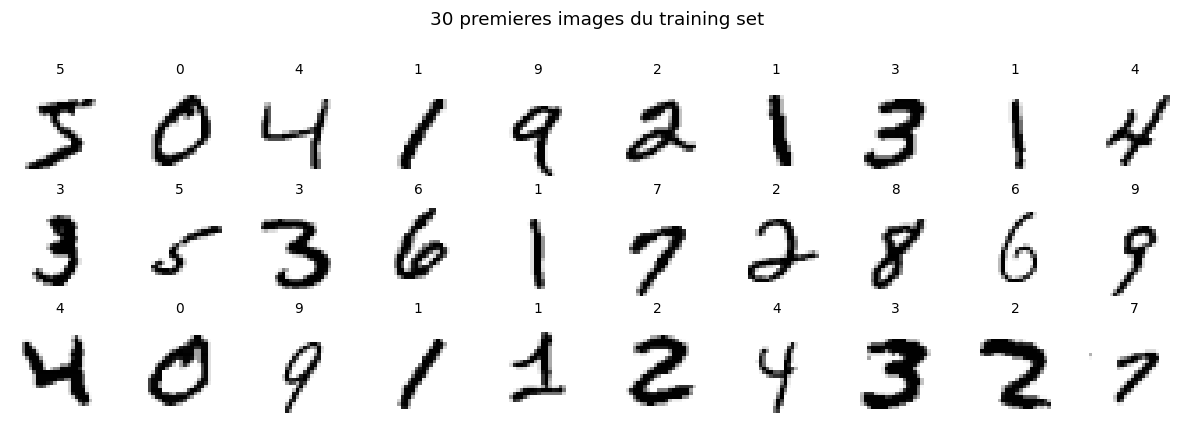

In [14]:
fig, axes = plt.subplots(3, 10, figsize=(11, 3.8))
for ax, img, label in zip(axes.ravel(), X_train[:30], y_train[:30]):
    ax.imshow(img.reshape(28, 28), cmap="binary")
    ax.set_title(int(label), fontsize=9)
    ax.axis("off")
fig.suptitle("30 premieres images du training set", y=1.02)
plt.tight_layout()
plt.show()

Observez deux propriétés, qui expliquent **pourquoi le k-NN marche si bien ici** :

- les chiffres sont **centrés** dans leur cadre de 28 × 28 ;
- ils sont **normalisés en taille**.

La distance euclidienne pixel à pixel entre deux images a donc un sens. Si les chiffres étaient
décalés de quelques pixels ou de tailles variables, deux images du même chiffre se retrouveraient
très éloignées au sens de cette distance, et le k-NN s'effondrerait.

C'est la nuance du point **B17-15** : le k-NN n'est pas magique, il est **bien conditionné ici**.
L'exercice 2 exploite précisément cette fragilité.

---
## 5. Baseline : k-NN par défaut

Avant d'optimiser quoi que ce soit, il faut un point de départ. On entraîne un
`KNeighborsClassifier` avec ses paramètres par défaut (`n_neighbors=5`, `weights="uniform"`) sur
un **sous-échantillon de 10 000 exemples**, pour que ce soit rapide.

Rappel du fonctionnement. Pour classer une image $x \in \mathbb{R}^{d}$, l'algorithme calcule sa
distance à **tous** les exemples mémorisés :

$$\lVert x - x^{(i)} \rVert_{2} = \sqrt{\sum_{j=1}^{d} \left(x_{j} - x_{j}^{(i)}\right)^{2}}$$

puis garde les $k$ plus proches et fait voter leurs étiquettes. Avec $n$ exemples mémorisés et
$d = 784$ features, chaque prédiction coûte $O(n \cdot d)$ en version naïve.

In [ ]:
N_SUB = 10_000
X_sub, y_sub = X_train[:N_SUB], y_train[:N_SUB]

knn_base = KNeighborsClassifier()

t0 = time.perf_counter()
knn_base.fit(X_sub, y_sub)
t_fit = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_sub = knn_base.predict(X_test[:2000])
t_pred = time.perf_counter() - t0

print(f"fit     : {t_fit:7.3f} s  (10 000 exemples memorises)")
print(f"predict : {t_pred:7.3f} s  (2 000 images a classer)")
print(f"\naccuracy sur cet echantillon : {accuracy_score(y_test[:2000], y_pred_sub):.4f}")

Le rapport entre les deux durées est l'enseignement principal de cette cellule.

Le `fit` est quasi instantané : il ne fait que ranger les données dans une structure de recherche
(`KDTree` ou `BallTree`). Toute la dépense est reportée sur le `predict`. C'est la définition d'un
**non-parametric algorithm** : il ne résume pas les données en paramètres, il les garde.

---
## 6. Combien de temps le grid search va-t-il coûter ?

Extrapolons **avant** de lancer quoi que ce soit de long. Le coût de prédiction croît linéairement
avec le nombre d'exemples mémorisés **et** avec le nombre de requêtes :

$$t \;\approx\; t_{\text{mesuré}} \times \frac{n_{\text{train}}}{10\,000} \times
\frac{n_{\text{requêtes}}}{2\,000}$$

In [ ]:
def estime_duree(t_ref, n_train, n_query, n_train_ref=N_SUB, n_query_ref=2000):
    # Extrapolation lineaire du temps de prediction d'un k-NN.
    return t_ref * (n_train / n_train_ref) * (n_query / n_query_ref)


t_full = estime_duree(t_pred, n_train=60_000, n_query=10_000)
print(f"predict final (60k memorises, 10k requetes) : ~{t_full:6.1f} s")

# Un GridSearchCV avec cv=3 et G combinaisons effectue G*3 entrainements.
# Chaque fold memorise 2/3 du train (40 000) et predit sur 1/3 (20 000).
G = 6
t_grid = G * 3 * estime_duree(t_pred, n_train=40_000, n_query=20_000)
print(f"\ngrid search ({G} combinaisons x 3 folds) :")
print(f"  sur 1 coeur  : ~{t_grid/60:6.1f} min")
print(f"  sur 8 coeurs : ~{t_grid/60/8:6.1f} min")

Ces chiffres sont approximatifs — les structures d'arbre utilisées par scikit-learn ne sont pas
exactement linéaires en $n$ — mais l'ordre de grandeur est juste.

**Si l'estimation annonce plusieurs heures**, réduisez la grille avant de lancer : par exemple
`n_neighbors` dans `[4, 5]` et `weights` fixé à `"distance"`.

---
## 7. Grid search, étape 1 : valider le code sur un sous-échantillon

**Ne sautez pas cette étape.** Elle coûte deux minutes et vous évite de découvrir une faute de
frappe après quarante minutes d'attente.

On lance exactement la même grille que la version finale, mais sur 10 000 exemples.

In [ ]:
param_grid = [
    {"n_neighbors": [3, 4, 5], "weights": ["uniform", "distance"]},
]

grid_test = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2,
)

t0 = time.perf_counter()
grid_test.fit(X_sub, y_sub)

print(f"\nduree : {time.perf_counter() - t0:.1f} s")
print("meilleurs parametres :", grid_test.best_params_)
print(f"meilleur score CV    : {grid_test.best_score_:.4f}")

Le code tourne, la grille est bien parcourue. On peut lancer la version sérieuse.

---
## 8. Grid search, étape 2 : la grille complète

**Cellule longue.** Selon votre machine, comptez entre quinze minutes et plus d'une heure.

- `n_jobs=-1` utilise tous les cœurs disponibles.
- `verbose=3` affiche chaque fold au fur et à mesure, pour que vous sachiez où vous en êtes.

In [ ]:
grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=3,
)

t0 = time.perf_counter()
grid_search.fit(X_train, y_train)

print(f"\nduree totale : {(time.perf_counter() - t0)/60:.1f} min")
print("meilleurs parametres :", grid_search.best_params_)
print(f"meilleur score CV    : {grid_search.best_score_:.4f}")

On regarde la grille entière, pas seulement le gagnant. Un écart de 0,001 entre deux
configurations ne veut rien dire : il faut le comparer à l'écart-type entre folds
(point **BHD-12**).

In [ ]:
import pandas as pd

res = pd.DataFrame(grid_search.cv_results_)
colonnes = [
    "param_n_neighbors",
    "param_weights",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]
res[colonnes].sort_values("rank_test_score").reset_index(drop=True)

**Résultat attendu** : `n_neighbors=4`, `weights="distance"`, autour de 97,1 % en
cross-validation.

Pourquoi `"distance"` l'emporte sur `"uniform"` : avec `"uniform"`, les $k$ voisins votent à poids
égal. Avec `"distance"`, chaque voisin $i$ pèse

$$w^{(i)} = \frac{1}{\lVert x - x^{(i)} \rVert_{2}}$$

donc un voisin collé à l'image pèse beaucoup plus qu'un voisin situé à la limite du rayon. C'est
d'autant plus utile avec un $k$ **pair** comme 4, où un vote uniforme produirait régulièrement des
égalités qu'il faudrait départager arbitrairement.

Comparez aussi `mean_test_score` et `std_test_score` : si l'écart-type dépasse la différence entre
le premier et le deuxième, le classement n'est pas fiable.

---
## 9. Évaluation finale — une seule fois

À partir d'ici, plus de retour en arrière.

`grid_search.best_estimator_` a déjà été réentraîné sur **tout** le training set
(`refit=True` est le défaut), donc il n'y a rien à refaire avant de prédire.

In [ ]:
final_model = grid_search.best_estimator_

t0 = time.perf_counter()
y_pred = final_model.predict(X_test)
print(f"predict sur 10 000 images : {time.perf_counter() - t0:.1f} s")

acc = accuracy_score(y_test, y_pred)
print(f"\nACCURACY SUR LE TEST SET : {acc:.4f}")
print("objectif 97 % :", "ATTEINT" if acc > 0.97 else "NON ATTEINT")

### Intervalle de confiance

Annoncer « 97,14 % » sans barre d'erreur est trompeur. Avec $n = 10\,000$ exemples de test et une
accuracy mesurée $\hat{p}$, l'intervalle à 95 % vaut approximativement

$$\hat{p} \;\pm\; 1{,}96 \sqrt{\frac{\hat{p}\,(1 - \hat{p})}{n}}$$

C'est le point **B03-13** appliqué ici : l'accuracy mesurée est une moyenne de $n$ variables de
Bernoulli (bien classé / mal classé), donc le théorème central limite s'applique.

In [ ]:
n_test = len(y_test)
marge = 1.96 * np.sqrt(acc * (1 - acc) / n_test)

print(f"accuracy = {acc:.4f}")
print(f"IC 95 %  = [{acc - marge:.4f} ; {acc + marge:.4f}]")
print(f"soit +/- {marge*100:.2f} points")

Retenez l'ordre de grandeur : sur 10 000 exemples de test, **deux modèles séparés par moins de
0,3 point ne sont pas distinguables**. Toute la littérature qui se dispute la quatrième décimale
sur MNIST se dispute du bruit.

---
## 10. Error analysis

Un score global ne dit pas *où* le modèle échoue. La confusion matrix, si (point **B17-14**).

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Confusion matrix normalisee par ligne (vraie classe)")
plt.tight_layout()
plt.show()

Normaliser **par ligne** (`normalize="true"`) donne, pour chaque vraie classe, la répartition des
prédictions. La diagonale est alors le **recall** de chaque classe :

$$\text{recall}_{k} = \frac{\text{nombre de } k \text{ correctement classés}}{\text{nombre total de } k}$$

Sans normalisation, les classes les plus nombreuses écrasent visuellement les autres.

Listons maintenant les erreurs hors diagonale les plus fréquentes.

In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm_erreurs = cm.copy()
np.fill_diagonal(cm_erreurs, 0)

erreurs = [
    (cm_erreurs[i, j], i, j)
    for i in range(10)
    for j in range(10)
    if cm_erreurs[i, j] > 0
]
erreurs.sort(reverse=True)

print("Les 10 confusions les plus frequentes :\n")
for compte, vrai, predit in erreurs[:10]:
    print(f"  un {vrai} classe en {predit} : {compte} fois")

In [ ]:
# Visualisation de la confusion la plus frequente
_, VRAI, PREDIT = erreurs[0]

masque = (y_test == VRAI) & (y_pred == PREDIT)
images = X_test[masque]
print(f"{len(images)} images de '{VRAI}' classees en '{PREDIT}'")

n_show = min(10, len(images))
fig, axes = plt.subplots(1, n_show, figsize=(1.25 * n_show, 1.9))
for ax, img in zip(np.atleast_1d(axes), images[:n_show]):
    ax.imshow(img.reshape(28, 28), cmap="binary")
    ax.axis("off")
fig.suptitle(f"Vrai = {VRAI}, predit = {PREDIT}", y=1.06)
plt.tight_layout()
plt.show()

Regardez ces images une par une et posez-vous la question du point **BHD-18** : s'agit-il d'une
erreur du modèle, ou de l'**irreducible error** ?

Beaucoup de ces chiffres sont illisibles pour un humain aussi. Dans ce cas, aucun réglage
d'hyperparamètre ne les récupérera. Il faudrait changer de **représentation** (c'est le sujet de
l'exercice 2) ou de **famille de modèles** (un CNN, phase 2 du carnet).

---
## 11. Bilan

### Ce qu'il faut retenir

| Constat | Pourquoi |
|---|---|
| Le `fit` du k-NN est gratuit, le `predict` est cher | C'est un **non-parametric algorithm** : il garde tout le training set au lieu de le résumer |
| `weights="distance"` bat `"uniform"` | Pondérer par $1/\lVert x - x^{(i)} \rVert_{2}$ évite les égalités et respecte la proximité réelle |
| Le k-NN excelle sur MNIST | Images centrées et normalisées : la distance euclidienne pixel à pixel a un sens |
| $97{,}1\ \% \pm 0{,}33$ point | Sur 10 000 exemples de test, la troisième décimale est du bruit |
| On valide le code avant de lancer la grille | Deux minutes investies, quarante économisées |

### Rattachement au carnet

- **B13-6** : jamais régler un hyperparamètre sur le test set.
- **B14-9** : ici les classes sont équilibrées, donc l'accuracy suffit — cas rare.
- **B17-14** : confusion matrix, recall par classe.
- **B17-15** : k-nearest neighbors, non-parametric, curse of dimensionality.
- **B03-13** : intervalle de confiance d'une proportion mesurée.
- **BHD-12** : deux scores proches ne se classent pas.
- **BHD-18** : error analysis, irreducible error.

### Suite

L'exercice 2 (data augmentation) reprend ce modèle comme baseline et lui ajoute une connaissance
du domaine. C'est la paire naturelle de celui-ci — faites les deux d'affilée.